# The Part-Time Penalty — Notebook 02: Occupation & Same-Wage Analysis
**Research question:** Do part-time postings advertise fewer essential benefits than full-time postings **within similar occupations and hourly wage bands**?

**Input:** `My Drive/The Part-Time Penalty/Cleaned Data/indeed_cleaned_part_time_penalty.csv.gz` from Notebook 01. **Do not upload the original ZIP again.**

**Outputs:** occupation audit, comparison tables, matched-strata analysis, charts, and a Tableau-ready CSV.

**Important:** We study **advertised benefit disclosure**, not verified employee eligibility. These are observational comparisons, not causal effects.

## 1. Mount Drive and load Notebook 01 output
Run this first. Change `ROOT` only if your Drive folder has a different name.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/content/drive/MyDrive/The Part-Time Penalty')
SOURCE = ROOT / 'Cleaned Data' / 'indeed_cleaned_part_time_penalty.csv.gz'
OUT = ROOT / 'Cleaned Data'
FIGS = ROOT / 'Visualizations' / 'Notebook 02'
OUT.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)
assert SOURCE.exists(), f'Missing file: {SOURCE}. Run Notebook 01 export first.'
df = pd.read_csv(SOURCE, low_memory=False)
print('Loaded:', f'{len(df):,}', 'rows')
print('Columns:', df.columns.tolist())
display(df[['job_title','employment_type','hourly_midpoint','salary_formatted']].head())

Mounted at /content/drive
Loaded: 140,816 rows
Columns: ['jobid', 'job_title', 'job_type', 'salary_formatted', 'benefits', 'location', 'company_name', 'date_posted_parsed', 'employment_type', 'hourly_min', 'hourly_max', 'hourly_midpoint', 'salary_parse_status', 'benefits_disclosed', 'health_insurance', 'paid_time_off', 'retirement', 'dental_insurance', 'flexible_schedule']


,job_title,employment_type,hourly_midpoint,salary_formatted
0,Operations Research Analyst - Journeyman - Sec...,Unknown/Other,NaN,NaN
1,Financial Advisor,Full-time,74.759615,"$61,000 - $250,000 a year"
2,Business Relationship Manager,Full-time,50.721154,"$71,000 - $140,000 a year"
3,Bilingual Videographer/Editor,Full-time,26.500000,$25 - $28 an hour
4,Physician Hematology Oncology,Full-time,275.480769,"$506,000 - $640,000 a year"


## 2. Validate input and define analysis population
Keep only unambiguous job types and wages from the corrected Notebook 01 parser. We also show the number of postings excluded at each step.

In [2]:
BENEFITS = ['health_insurance','paid_time_off','retirement','dental_insurance','flexible_schedule']
required = ['job_title','jobid','employment_type','hourly_midpoint','benefits_disclosed','salary_formatted'] + BENEFITS
missing_cols = [c for c in required if c not in df.columns]
assert not missing_cols, f'Missing columns: {missing_cols}. Re-export Notebook 01: {missing_cols}'
for c in BENEFITS + ['benefits_disclosed']:
    df[c] = df[c].astype('string').str.strip().str.lower().map({'true':True,'false':False,'1':True,'0':False}).fillna(False).astype(bool)
df['hourly_midpoint'] = pd.to_numeric(df['hourly_midpoint'], errors='coerce')
valid_type = df['employment_type'].isin(['Full-time','Part-time'])
valid_wage = df['hourly_midpoint'].between(5,500,inclusive='both')
print('All cleaned postings:',f'{len(df):,}')
print('Unambiguous FT/PT:',f'{valid_type.sum():,}')
print('FT/PT with usable hourly wage:',f'{(valid_type & valid_wage).sum():,}')
print('Missing/blank job titles among usable:',f'{df.loc[valid_type & valid_wage,"job_title"].isna().sum():,}')
analysis = df.loc[valid_type & valid_wage].copy()
print('Analysis sample by employment type:')
display(analysis['employment_type'].value_counts().to_frame('postings'))

All cleaned postings: 140,816
Unambiguous FT/PT: 96,993
FT/PT with usable hourly wage: 81,398
Missing/blank job titles among usable: 0
Analysis sample by employment type:


,postings
employment_type,
Full-time,66311
Part-time,15087


## 3. Explore actual job titles BEFORE grouping
The categories below are **transparent heuristic labels**, not official occupational codes. Inspect the most common titles and review misclassifications before presenting results.

In [3]:
print('Top 45 job titles in the analysis sample:')
display(analysis['job_title'].fillna('(missing)').value_counts().head(45).to_frame('postings'))
print('Sample part-time titles:')
display(analysis.loc[analysis.employment_type.eq('Part-time'),['job_title','company_name','hourly_midpoint']].sample(min(20,(analysis.employment_type=='Part-time').sum()),random_state=42))

Top 45 job titles in the analysis sample:


,postings
job_title,
Service Team,315
Cook,312
Sales Associate,311
Kitchen Team,294
Team Member,269
Dishwasher,225
Customer Service Associate I,215
Cashier,208
Customer Service Representative,193


Sample part-time titles:


,job_title,company_name,hourly_midpoint
127373,Support Associate,Chico's,19.000000
134249,PRN SLPA,Melospeech Inc,46.475000
78730,Retail Merchandiser - Overnight,The Retail Odyssey Company,16.900000
29735,Assisted Living Cook,AAA Kindness Care Home,18.500000
111929,Valet USA,Metropolis Technologies,19.000000
9272,Part-Time (Adjunct) Faculty - AOJ,West Hills Community College District,76.500000
42963,PSYCHOLOGIST,TOP MALIBU REHAB CENTER,132.500000
34046,Behavior Respite Companion - Respite Caregiver...,Institute for Applied Behavior Analysis,21.000000
103077,Caregivers for Senior Care,"Cambrian Homecare, Inc.",19.000000
104756,Front Crew - Ono 063,Ono Hawaiian BBQ,20.000000


## 4. Assign occupation groups from job titles
We prioritize specific healthcare, education, logistics, retail, hospitality, administration, technology, and maintenance keywords. Everything else stays **Other / Unclassified** rather than being forced into a category. Edit patterns after inspecting titles; rerun the remaining cells if you change them.

In [4]:
# Order matters: first matching group wins. Review examples in the next cell.
OCCUPATION_PATTERNS = [
 ('Healthcare', r'\b(?:nurs(?:e|ing)|rn\b|lpn\b|lvn\b|cna\b|medical assistant|medical receptionist|patient care|caregiver|home health|physical therap|occupational therap|pharmac(?:ist|y tech)|dental assistant|dental hygienist|radiolog|physician|doctor|clinical|hospital|veterinar|vet tech|behavior technician)\b'),
 ('Education & Childcare', r'\b(?:teacher|tutor|instructor|educator|teaching assistant|paraprofessional|substitute teacher|childcare|child care|daycare|preschool|babysitter|nanny|camp counselor|after.school)\b'),
 ('Retail & Sales', r'\b(?:retail|cashier|store associate|sales associate|sales representative|salesperson|merchandis|stock associate|store manager|customer sales|brand ambassador)\b'),
 ('Food & Hospitality', r'\b(?:restaurant|server|waiter|waitress|bartender|barista|cook|chef|dishwasher|food service|food prep|kitchen|hostess|hotel|front desk hotel|housekeeping|banquet|catering|bakery|baker|busser)\b'),
 ('Logistics & Transportation', r'\b(?:warehouse|delivery driver|truck driver|driver|courier|forklift|package handler|shipping|receiving|inventory associate|material handler|logistics|dispatcher|distribution center)\b'),
 ('Office & Administration', r'\b(?:administrative|admin assistant|office assistant|office manager|receptionist|data entry|executive assistant|secretary|bookkeeper|payroll|accounting clerk|customer service|call center|scheduler|records clerk|clerical)\b'),
 ('Technology & Engineering', r'\b(?:software|developer|programmer|data analyst|data scientist|engineer|it support|help desk|cybersecurity|network technician|web designer|qa analyst|systems analyst|computer technician)\b'),
 ('Facilities & Maintenance', r'\b(?:janitor|custodian|cleaner|maintenance|landscap|groundskeeper|security guard|security officer|electrician|plumber|hvac|mechanic|technician maintenance|facilities)\b'),
]

def classify_occupation(title):
    if pd.isna(title) or not str(title).strip():
        return 'Other / Unclassified'
    t = str(title).lower()
    for name, pattern in OCCUPATION_PATTERNS:
        if re.search(pattern, t, flags=re.IGNORECASE):
            return name
    return 'Other / Unclassified'

analysis['occupation'] = analysis['job_title'].map(classify_occupation)
occupation_counts = (analysis.groupby(['occupation','employment_type']).size()
                     .unstack(fill_value=0).reindex(columns=['Full-time','Part-time'],fill_value=0))
occupation_counts['Total'] = occupation_counts.sum(axis=1)
display(occupation_counts.sort_values('Total',ascending=False))
print('Unclassified share:',f"{analysis.occupation.eq('Other / Unclassified').mean():.1%}")

employment_type,Full-time,Part-time,Total
occupation,,,
Other / Unclassified,40702,7713,48415
Technology & Engineering,10756,55,10811
Healthcare,4424,1308,5732
Retail & Sales,1836,2243,4079
Food & Hospitality,1917,1593,3510
Office & Administration,2387,585,2972
Facilities & Maintenance,2011,274,2285
Logistics & Transportation,1755,289,2044
Education & Childcare,523,1027,1550


Unclassified share: 59.5%


## 5. Quality check: inspect 50 classified titles
**Required manual step.** The group names are useful only if the underlying titles fit. Review 5 random examples per category where possible. If the classification looks poor, refine the regex in Step 4 and rerun.

In [5]:
audit_samples = []
for occ, group in analysis.groupby('occupation'):
    audit_samples.append(group[['job_title','occupation','employment_type','hourly_midpoint']]
                         .sample(n=min(6,len(group)),random_state=2026))
audit = pd.concat(audit_samples,ignore_index=True)
display(audit)
audit.to_csv(OUT/'02_occupation_classification_audit.csv',index=False)
print('Saved occupation audit. Manually mark questionable titles before interpreting results.')

,job_title,occupation,employment_type,hourly_midpoint
0,After School Dance Facilitator,Education & Childcare,Part-time,57.500000
1,ECE Teacher at Learning Jungle Valley Center,Education & Childcare,Full-time,22.500000
2,Part-Time Instructor Pool - Noncredit - Parent...,Education & Childcare,Part-time,73.590000
3,"Lead Teacher - Irvine, CA",Education & Childcare,Full-time,21.380000
4,Academic Tutor,Education & Childcare,Part-time,26.000000
5,Marine Science Educator,Education & Childcare,Part-time,29.000000
6,Swimming Pool Service Technician for Cleaning ...,Facilities & Maintenance,Part-time,23.000000
7,Security Officer - DAILY,Facilities & Maintenance,Part-time,22.840000
8,Maintenance Technician - Promenade Towers R019...,Facilities & Maintenance,Full-time,25.000000
9,Night Maintenance,Facilities & Maintenance,Full-time,18.465000


Saved occupation audit. Manually mark questionable titles before interpreting results.


## 6. Raw occupation-level benefit gaps
Rates are the share of **all postings in that group** explicitly listing a benefit. Minimum sample threshold: **30 full-time and 30 part-time postings** for each occupation. Small groups are omitted from comparison charts but retained in exported counts.

Occupations meeting threshold: ['Education & Childcare', 'Facilities & Maintenance', 'Food & Hospitality', 'Healthcare', 'Logistics & Transportation', 'Office & Administration', 'Other / Unclassified', 'Retail & Sales', 'Technology & Engineering']


,occupation,employment_type,postings,health_insurance,paid_time_off,retirement,dental_insurance,flexible_schedule
0,Education & Childcare,Full-time,523,55.83,38.62,52.77,53.73,5.74
1,Education & Childcare,Part-time,1027,11.78,12.27,19.47,13.44,24.15
2,Facilities & Maintenance,Full-time,2011,59.32,44.90,55.35,54.05,4.08
3,Facilities & Maintenance,Part-time,274,18.61,16.42,22.26,16.06,17.52
4,Food & Hospitality,Full-time,1917,66.30,31.09,61.29,63.80,31.51
5,Food & Hospitality,Part-time,1593,45.07,21.72,43.75,50.53,15.51
6,Healthcare,Full-time,4424,56.24,45.43,53.14,52.80,10.80
7,Healthcare,Part-time,1308,32.57,35.24,37.31,30.28,27.52
8,Logistics & Transportation,Full-time,1755,63.59,51.28,56.30,60.68,6.61
9,Logistics & Transportation,Part-time,289,26.64,26.64,28.03,27.68,17.65


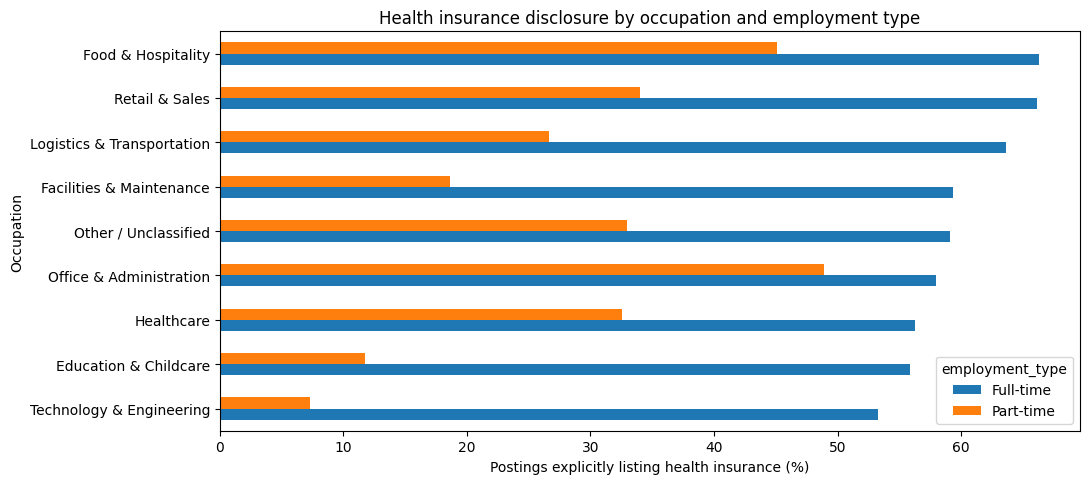

In [6]:
MIN_GROUP = 30
occ_counts = analysis.groupby(['occupation','employment_type']).size().unstack(fill_value=0)
eligible_occ = occ_counts.index[(occ_counts.get('Full-time',0)>=MIN_GROUP) & (occ_counts.get('Part-time',0)>=MIN_GROUP)]
print('Occupations meeting threshold:',list(eligible_occ))
occ_summary = (analysis.groupby(['occupation','employment_type'])
               .agg(postings=('job_title','size'), **{c:(c,'mean') for c in BENEFITS})
               .reset_index())
for c in BENEFITS: occ_summary[c] *= 100
display(occ_summary.round(2))
occ_summary.to_csv(OUT/'02_occupation_benefit_rates.csv',index=False)

if len(eligible_occ):
    pivot = occ_summary[occ_summary.occupation.isin(eligible_occ)].pivot(index='occupation',columns='employment_type',values='health_insurance').reindex(columns=['Full-time','Part-time'])
    ax=pivot.sort_values('Full-time',ascending=True).plot(kind='barh',figsize=(11,max(4,len(pivot)*.55)))
    ax.set(xlabel='Postings explicitly listing health insurance (%)',ylabel='Occupation',title='Health insurance disclosure by occupation and employment type')
    plt.tight_layout();plt.savefig(FIGS/'01_health_insurance_by_occupation.png',dpi=180,bbox_inches='tight');plt.show()
else: print('No occupations meet the minimum count; inspect classification and sample sizes.')

## 7. Same occupation **and** same wage band
This is the project key comparison. We only display occupation × wage-band cells with **at least 30 postings of each employment type**. Otherwise the apparent gap may be too unstable to emphasize.

In [7]:
WAGE_BINS=[0,15,20,25,30,40,60,np.inf]
WAGE_LABELS=['<$15','$15–20','$20–25','$25–30','$30–40','$40–60','$60+']
analysis['wage_band']=pd.cut(analysis['hourly_midpoint'],bins=WAGE_BINS,labels=WAGE_LABELS,right=False)
strata=(analysis.groupby(['occupation','wage_band','employment_type'],observed=True)
        .agg(n=('job_title','size'), **{c:(c,'mean') for c in BENEFITS}).reset_index())
for c in BENEFITS: strata[c] *= 100
key=['occupation','wage_band']
wide=strata.pivot(index=key,columns='employment_type',values=['n']+BENEFITS)
wide.columns=[f'{metric}_{kind.replace("-","_").lower()}' for metric,kind in wide.columns]
wide=wide.reset_index()
for kind in ['full_time','part_time']:
    col=f'n_{kind}'
    if col not in wide:wide[col]=0
wide[['n_full_time','n_part_time']]=wide[['n_full_time','n_part_time']].fillna(0).astype(int)
wide['eligible']=wide['n_full_time'].ge(MIN_GROUP) & wide['n_part_time'].ge(MIN_GROUP)
for benefit in BENEFITS:
    f,p=f'{benefit}_full_time',f'{benefit}_part_time'
    if f in wide and p in wide:wide[f'{benefit}_gap_pp']=wide[f]-wide[p]
print('Occupation × wage-band combinations with both groups >=',MIN_GROUP,':',int(wide.eligible.sum()))
cols=['occupation','wage_band','n_full_time','n_part_time','health_insurance_gap_pp','paid_time_off_gap_pp','retirement_gap_pp']
matched=wide.loc[wide.eligible,cols].copy()
display(matched.sort_values('health_insurance_gap_pp',ascending=False).round(2).head(25))
wide.to_csv(OUT/'02_all_occupation_wage_strata.csv',index=False)
matched.to_csv(OUT/'02_reliable_occupation_wage_comparisons.csv',index=False)
if matched.empty: print('No matched cells meet threshold. Try MIN_GROUP=15 only as an explicitly labeled exploratory sensitivity analysis; do not claim robust comparisons.')

Occupation × wage-band combinations with both groups >= 30 : 35


,occupation,wage_band,n_full_time,n_part_time,health_insurance_gap_pp,paid_time_off_gap_pp,retirement_gap_pp
53,Retail & Sales,$30–40,404,76,73.62,61.91,59.05
3,Education & Childcare,$25–30,112,161,57.73,41.30,31.33
42,Other / Unclassified,<$15,48,48,50.00,39.58,54.17
2,Education & Childcare,$20–25,139,270,48.95,28.74,31.69
38,Office & Administration,$25–30,514,55,47.65,30.13,31.36
37,Office & Administration,$20–25,711,130,47.25,24.52,34.50
4,Education & Childcare,$30–40,122,114,44.62,24.72,35.50
30,Logistics & Transportation,$20–25,638,129,42.54,20.73,30.82
17,Food & Hospitality,$25–30,424,90,39.95,-10.15,28.56
18,Food & Hospitality,$30–40,209,34,39.22,20.97,36.90


## 8. Heatmap of health-insurance disclosure gaps
Positive values mean full-time postings list health insurance more frequently. Blank cells do **not** mean a zero gap; they mean the cell did not meet the minimum sample threshold.

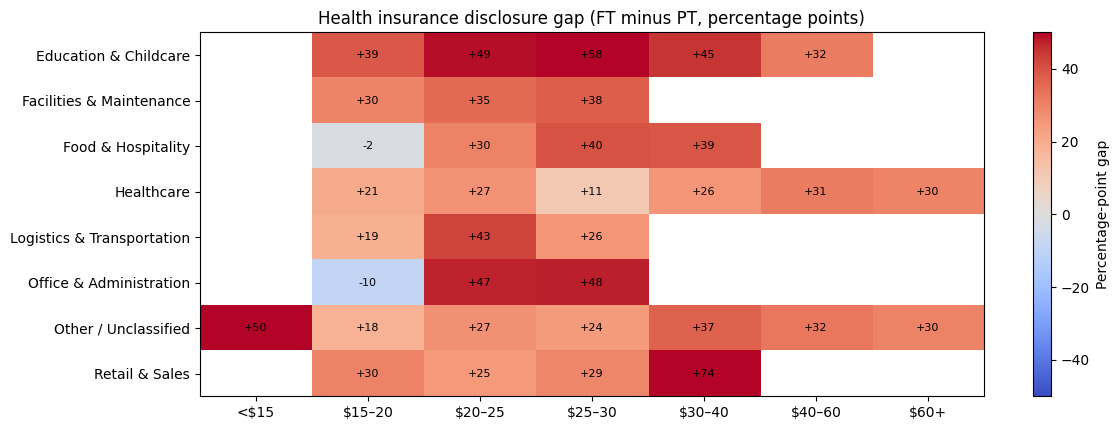

In [8]:
if not matched.empty:
    matrix=matched.pivot(index='occupation',columns='wage_band',values='health_insurance_gap_pp').reindex(columns=WAGE_LABELS)
    fig,ax=plt.subplots(figsize=(12,max(4,len(matrix)*.55)))
    im=ax.imshow(matrix.to_numpy(dtype=float),aspect='auto',cmap='coolwarm',vmin=-50,vmax=50)
    ax.set_xticks(np.arange(len(matrix.columns)),labels=matrix.columns)
    ax.set_yticks(np.arange(len(matrix.index)),labels=matrix.index)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            v=matrix.iat[i,j]
            if pd.notna(v):ax.text(j,i,f'{v:+.0f}',ha='center',va='center',fontsize=8)
    ax.set_title('Health insurance disclosure gap (FT minus PT, percentage points)')
    fig.colorbar(im,ax=ax,label='Percentage-point gap')
    plt.tight_layout();plt.savefig(FIGS/'02_matched_wage_occupation_heatmap.png',dpi=180,bbox_inches='tight');plt.show()
else:print('Heatmap skipped: no reliable matched cells.')

## 9. Fairer overall summary: matched-strata weighted gap
This summary averages within occupation × wage-band cells that have sufficient data for both types. Each cell is weighted by the **smaller** of its full-time and part-time sample counts, preventing very large one-sided cells from dominating. This is a descriptive matched-strata summary, **not a causal estimate**.

,benefit,weighted_gap_pp,matched_cells,matched_weight
0,health_insurance,26.81,35,11622
3,dental_insurance,23.95,35,11622
2,retirement,19.18,35,11622
1,paid_time_off,18.55,35,11622
4,flexible_schedule,-8.87,35,11622


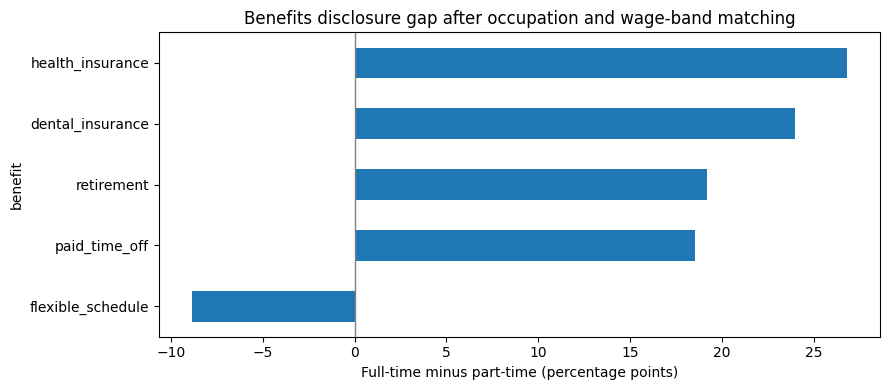

In [9]:
eligible=wide[wide['eligible']].copy()
if not eligible.empty:
    eligible['weight']=eligible[['n_full_time','n_part_time']].min(axis=1)
    summary=[]
    for benefit in BENEFITS:
        gap=f'{benefit}_gap_pp'
        if gap not in eligible:continue
        valid=eligible[gap].notna()
        if valid.any():
            avg=np.average(eligible.loc[valid,gap],weights=eligible.loc[valid,'weight'])
            summary.append({'benefit':benefit,'weighted_gap_pp':avg,'matched_cells':int(valid.sum()),'matched_weight':int(eligible.loc[valid,'weight'].sum())})
    weighted=pd.DataFrame(summary).sort_values('weighted_gap_pp',ascending=False)
    display(weighted.round(2))
    weighted.to_csv(OUT/'02_matched_strata_weighted_gaps.csv',index=False)
    ax=weighted.set_index('benefit')['weighted_gap_pp'].sort_values().plot(kind='barh',figsize=(9,4))
    ax.axvline(0,color='gray',linewidth=1)
    ax.set(xlabel='Full-time minus part-time (percentage points)',title='Benefits disclosure gap after occupation and wage-band matching')
    plt.tight_layout();plt.savefig(FIGS/'03_matched_strata_weighted_gaps.png',dpi=180,bbox_inches='tight');plt.show()
else:print('No reliable matched cells; weighted summary skipped.')

## 10. Robustness check: disclosed-benefits-only sample
Restrict to postings that list at least one benefit. This helps reveal how much of the main gap reflects **posting disclosure behavior** rather than the mix of specific benefits among postings that disclose any. This changes the denominator and should be reported as a sensitivity check, not the primary result.

In [10]:
disclosed=analysis.loc[analysis['benefits_disclosed']].copy()
print('Postings with >=1 listed benefit:',f'{len(disclosed):,}')
print('Counts by employment type:')
display(disclosed.employment_type.value_counts())
if not disclosed.empty:
    sens=disclosed.groupby('employment_type')[BENEFITS].mean().mul(100).reindex(['Full-time','Part-time'])
    display(sens.round(2))
    sens.to_csv(OUT/'02_disclosed_only_rates.csv')
    sens_strata=(disclosed.groupby(['occupation','wage_band','employment_type'],observed=True)
                 .agg(n=('job_title','size'),health=('health_insurance','mean')).reset_index())
    ss=sens_strata.pivot(index=['occupation','wage_band'],columns='employment_type',values=['n','health'])
    ss.columns=[f'{a}_{b}' for a,b in ss.columns]
    ss=ss.dropna(subset=['n_Full-time','n_Part-time','health_Full-time','health_Part-time']) if set(['n_Full-time','n_Part-time','health_Full-time','health_Part-time']).issubset(ss.columns) else pd.DataFrame()
    if not ss.empty:
        ss=ss[(ss['n_Full-time']>=MIN_GROUP)&(ss['n_Part-time']>=MIN_GROUP)].copy()
        if not ss.empty:
            ss['health_gap_pp']=(ss['health_Full-time']-ss['health_Part-time'])*100
            display(ss[['n_Full-time','n_Part-time','health_gap_pp']].round(2).head(20))
            ss.to_csv(OUT/'02_disclosed_only_matched_cells.csv')
        else:print('No disclosed-only matched cells pass the minimum threshold.')

Postings with >=1 listed benefit: 56,042
Counts by employment type:


,count
employment_type,
Full-time,46613
Part-time,9429


,health_insurance,paid_time_off,retirement,dental_insurance,flexible_schedule
employment_type,,,,,
Full-time,83.09,61.42,75.44,75.26,10.40
Part-time,52.91,39.21,55.99,51.77,30.54


n_Full-time  n_Part-time  health_gap_pp
occupation                 wage_band                                         
Education & Childcare      $20–25           109.0        143.0          55.39
                           $25–30            93.0        106.0          67.17
                           $30–40            87.0         65.0          60.11
                           $40–60            54.0         64.0          55.21
Facilities & Maintenance   $15–20            94.0         51.0          41.36
                           $20–25           299.0         57.0          35.49
Food & Hospitality         $15–20           182.0        708.0          12.96
                           $20–25           683.0        316.0          19.72
                           $25–30           332.0         48.0          31.75
Healthcare                 $15–20           103.0         72.0          22.41
                           $20–25           413.0        374.0          37.86
                           $25–30           306.0        126.0          27.59
                           $30–40           321.0         70.0          31.67
                           $40–60           702.0        109.0          36.15
                           $60+            1260.0        145.0          28.15
Logistics & Transportation $15–20           193.0         57.0          18.67
                           $20–25           498.0         94.0          52.66
Office & Administration    $15–20           166.0        311.0           2.30
                           $20–25           546.0         75.0          56.56
                           $25–30           388.0         31.0          58.22

## 11. Check the salary assumption (hourly-only sensitivity)
Notebook 01 converts annual salaries assuming 2,080 work hours/year. For part-time roles this assumption can be inaccurate. As a robustness check, restrict to salary strings explicitly labeled **per hour** and repeat the within-cell analysis.

In [11]:
hourly_pattern=r'\b(?:hour|hourly|hora|horas)\b'
hourly_only=analysis[analysis['salary_formatted'].fillna('').str.contains(hourly_pattern,case=False,regex=True)].copy()
print('Hourly-labeled salary postings:',f'{len(hourly_only):,}')
display(hourly_only['employment_type'].value_counts())
hourly_strata=(hourly_only.groupby(['occupation','wage_band','employment_type'],observed=True)
               .agg(n=('job_title','size'),health=('health_insurance','mean')).reset_index())
hw=hourly_strata.pivot(index=['occupation','wage_band'],columns='employment_type',values=['n','health'])
hw.columns=[f'{a}_{b}' for a,b in hw.columns]
needed=['n_Full-time','n_Part-time','health_Full-time','health_Part-time']
if set(needed).issubset(hw.columns):
    hw=hw.dropna(subset=needed)
    hw=hw[(hw['n_Full-time']>=MIN_GROUP)&(hw['n_Part-time']>=MIN_GROUP)].copy()
    if not hw.empty:
        hw['health_gap_pp']=(hw['health_Full-time']-hw['health_Part-time'])*100
        print('Hourly-only matched cells:',len(hw))
        display(hw[needed+['health_gap_pp']].round(2).head(25))
        hw.to_csv(OUT/'02_hourly_only_matched_cells.csv')
    else:print('No hourly-only matched cells meet threshold.')
else:print('Hourly-only sample does not contain both job types.')

Hourly-labeled salary postings: 41,341


,count
employment_type,
Full-time,26712
Part-time,14629


Hourly-only matched cells: 33


n_Full-time  n_Part-time  \
occupation                 wage_band                             
Education & Childcare      $15–20            32.0        107.0   
                           $20–25           128.0        263.0   
                           $25–30           101.0        154.0   
                           $30–40            55.0        113.0   
Facilities & Maintenance   $15–20           143.0         99.0   
                           $20–25           381.0        110.0   
                           $25–30           350.0         35.0   
Food & Hospitality         $15–20           309.0        961.0   
                           $20–25           805.0        487.0   
                           $25–30           412.0         90.0   
                           $30–40            76.0         34.0   
Healthcare                 $15–20           116.0         85.0   
                           $20–25           515.0        439.0   
                           $25–30           432.0        154.0   
                           $30–40           353.0        106.0   
                           $40–60           496.0        153.0   
                           $60+             757.0        271.0   
Logistics & Transportation $15–20           264.0         91.0   
                           $20–25           621.0        128.0   
                           $25–30           274.0         33.0   
Office & Administration    $15–20           218.0        357.0   
                           $20–25           641.0        128.0   
                           $25–30           418.0         55.0   
Other / Unclassified       $15–20          1647.0       2407.0   
                           $20–25          4632.0       2855.0   

                                      health_Full-time  health_Part-time  \
occupation                 wage_band                                       
Education & Childcare      $15–20                 0.47              0.10   
                           $20–25                 0.60              0.12   
                           $25–30                 0.68              0.07   
                           $30–40                 0.51              0.07   
Facilities & Maintenance   $15–20                 0.43              0.12   
                           $20–25                 0.58              0.22   
                           $25–30                 0.59              0.17   
Food & Hospitality         $15–20                 0.45              0.47   
                           $20–25                 0.76              0.46   
                           $25–30                 0.72              0.32   
                           $30–40                 0.54              0.21   
Healthcare                 $15–20                 0.55              0.35   
                           $20–25                 0.65              0.37   
                           $25–30                 0.57              0.45   
                           $30–40                 0.55              0.29   
                           $40–60                 0.62              0.29   
                           $60+                   0.41              0.21   
Logistics & Transportation $15–20                 0.53              0.34   
                           $20–25                 0.62              0.20   
                           $25–30                 0.66              0.39   
Office & Administration    $15–20                 0.63              0.72   
                           $20–25                 0.60              0.12   
                           $25–30                 0.60              0.11   
Other / Unclassified       $15–20                 0.52              0.33   
                           $20–25                 0.64              0.36   

                                      health_gap_pp  
occupation                 wage_band                 
Education & Childcare      $15–20             36.59  
                           $20–25       

## 12. Export Tableau-ready data and project evidence
The Tableau file contains posting-level labels and flags but excludes free-text job descriptions and personally identifying details. Use **filters** for occupation, wage band, employment type, and benefits. Avoid treating all California postings as Bay Area without verifying locations.

In [12]:
tableau_cols=['jobid','company_name','job_title','location','employment_type','occupation','hourly_midpoint','wage_band','benefits_disclosed']+BENEFITS
export=analysis[tableau_cols].copy()
export.to_csv(OUT/'02_tableau_part_time_penalty.csv.gz',index=False,compression='gzip')
occupation_counts.to_csv(OUT/'02_occupation_counts.csv')
print('Saved Tableau data:',OUT/'02_tableau_part_time_penalty.csv.gz')
print('Saved occupation counts, classification audit, matched comparisons and sensitivity outputs to:',OUT)
print('Saved charts to:',FIGS)
print('Total Tableau rows:',f'{len(export):,}')
print('\nNEXT: Review classification audit, then write 3 evidence-backed findings with actual denominators.')

Saved Tableau data: /content/drive/MyDrive/The Part-Time Penalty/Cleaned Data/02_tableau_part_time_penalty.csv.gz
Saved occupation counts, classification audit, matched comparisons and sensitivity outputs to: /content/drive/MyDrive/The Part-Time Penalty/Cleaned Data
Saved charts to: /content/drive/MyDrive/The Part-Time Penalty/Visualizations/Notebook 02
Total Tableau rows: 81,398

NEXT: Review classification audit, then write 3 evidence-backed findings with actual denominators.


## Notebook 02 completion checklist
- [ ] Inspect the top job titles and manually review the occupation audit CSV
- [ ] Confirm at least a few occupation × wage-band cells have **30+ full-time and 30+ part-time** postings
- [ ] Save the heatmap and weighted gap figure (if sample sizes permit)
- [ ] Compare main findings against **disclosed-only** and **hourly-only** sensitivity results
- [ ] Export `02_tableau_part_time_penalty.csv.gz`
- [ ] **File → Download → Download .ipynb** after all cells run; upload the completed notebook here

**Presentation caveats:** Posting disclosures are not proof of actual eligibility. Regex occupation groups can misclassify titles. Salary conversions are approximate. Differences are observational, not caused by employment type alone.